In [2]:
# ============================================================
# 라이브러리 및 데이터 로드
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score


plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False


PROJECT_DIR = Path.cwd().parents[3]

DATA_DIR = PROJECT_DIR / "data"
V2_DATA_DIR = DATA_DIR / "v2_5year_seoul"
PROCESSED_DIR = V2_DATA_DIR / "processed"

FINAL_PATH = (
    PROCESSED_DIR
    / "df_final_v1.parquet"
)


df = pd.read_parquet(
    FINAL_PATH
)

print("데이터:", df.shape)
print("파일 존재:", FINAL_PATH.exists())

print(
    "기간:",
    df["거래월일자"].min(),
    "~",
    df["거래월일자"].max(),
)

데이터: (234302, 124)
파일 존재: True
기간: 2021-07-01 00:00:00 ~ 2026-06-01 00:00:00


2021-07 ~ 2025-12  
→ 군집 생성  

2026-01 ~ 2026-06  
→ 생성된 군집을 적용  
→ 군집별 회귀 성능 분석  

In [3]:
# ============================================================
# 군집 학습 / Test 기간 분리
# ============================================================

cluster_train_df = df[
    df["거래월일자"] < "2026-01-01"
].copy()

cluster_test_df = df[
    df["거래월일자"] >= "2026-01-01"
].copy()


print(
    "군집 학습:",
    f"{len(cluster_train_df):,}건",
)

print(
    "Test:",
    f"{len(cluster_test_df):,}건",
)

print(
    "학습 단지 수:",
    cluster_train_df[
        "단지일련번호"
    ].nunique(),
)

군집 학습: 194,733건
Test: 39,569건
학습 단지 수: 7581


In [4]:
# ============================================================
# 군집 V1 Feature
# ============================================================

cluster_feature_cols = [
    # 주택 특성
    "전용면적",
    "연식",
    "층",

    # 공간
    "위도",
    "경도",

    # 교육
    "유치원거리_m",
    "초등학교거리_m",
    "중학교거리_m",
    "고등학교거리_m",

    # 교통
    "역세권거리_m",

    # 생활 / 업무
    "응급의료기관거리_m",
    "대규모점포거리_m",
    "주요일자리거리_m",
]

print(
    "군집 Feature 수:",
    len(cluster_feature_cols),
)

군집 Feature 수: 13


In [5]:
# ============================================================
# 단지 ID 기본 검증
# ============================================================

print(
    "단지일련번호 결측:",
    cluster_train_df[
        "단지일련번호"
    ].isna().sum(),
)

print(
    "단지 수:",
    cluster_train_df[
        "단지일련번호"
    ].nunique(),
)

complex_counts = (
    cluster_train_df[
        "단지일련번호"
    ]
    .value_counts()
)

display(
    complex_counts.describe()
)

단지일련번호 결측: 0
단지 수: 7581


count    7581.000000
mean       25.686981
std        53.080526
min         1.000000
25%         2.000000
50%         6.000000
75%        25.000000
max      1085.000000
Name: count, dtype: float64

In [6]:
# ============================================================
# 단지 단위 군집 데이터 생성
# ============================================================

complex_df = (
    cluster_train_df
    .groupby("단지일련번호")
    .agg(
        단지명=("단지명", "first"),
        법정동=("법정동", "first"),
        거래건수=("transaction_id", "size"),

        # 주택 특성
        전용면적=("전용면적", "median"),
        건축년도=("건축년도", "median"),
        층=("층", "median"),

        # 공간
        위도=("위도", "median"),
        경도=("경도", "median"),

        # 교육
        유치원거리_m=("유치원거리_m", "median"),
        초등학교거리_m=("초등학교거리_m", "median"),
        중학교거리_m=("중학교거리_m", "median"),
        고등학교거리_m=("고등학교거리_m", "median"),

        # 교통
        역세권거리_m=("역세권거리_m", "median"),

        # 생활 / 업무
        응급의료기관거리_m=("응급의료기관거리_m", "median"),
        대규모점포거리_m=("대규모점포거리_m", "median"),
        주요일자리거리_m=("주요일자리거리_m", "median"),
    )
    .reset_index()
)

# 2025년 말 기준 단지 연식
complex_df["기준연식"] = (
    2025
    - complex_df["건축년도"]
)

print(
    "단지 데이터:",
    complex_df.shape,
)

display(
    complex_df.head()
)

단지 데이터: (7581, 18)


,단지일련번호,단지명,법정동,거래건수,전용면적,건축년도,층,위도,경도,유치원거리_m,초등학교거리_m,중학교거리_m,고등학교거리_m,역세권거리_m,응급의료기관거리_m,대규모점포거리_m,주요일자리거리_m,기준연식
0,11110-101,크래스빌,평창동,2,185.20,2003.0,3.5,37.608520,126.974203,712.566751,1296.503413,1747.844193,635.342932,3020.956750,3720.835999,3438.306788,3954.796658,22.0
1,11110-102,현대뜨레비앙,익선동,56,46.64,2003.0,5.0,37.575114,126.990058,238.146726,168.497780,776.048260,644.051185,287.541968,864.937610,385.989878,19.536114,22.0
2,11110-107,경희궁파크팰리스,내수동,13,146.33,2003.0,13.0,37.574170,126.970544,145.597501,487.673416,662.693783,662.693783,325.663252,671.265175,774.784827,1153.013723,22.0
3,11110-111,창림,창신동,1,58.62,1994.0,3.0,37.576000,127.009360,375.649908,434.520432,480.484225,480.583185,498.109449,1002.851597,590.648630,1721.153827,31.0
4,11110-112,신현(102동),신교동,1,121.96,2002.0,5.0,37.583428,126.968155,234.843652,293.323506,438.529646,407.186761,969.192395,1287.057291,1674.854056,2120.624419,23.0


In [7]:
# ============================================================
# 군집 V1 최종 Feature
# ============================================================

cluster_feature_cols = [
    # 주택 특성
    "전용면적",
    "기준연식",
    "층",

    # 공간
    "위도",
    "경도",

    # 교육
    "유치원거리_m",
    "초등학교거리_m",
    "중학교거리_m",
    "고등학교거리_m",

    # 교통
    "역세권거리_m",

    # 생활 / 업무
    "응급의료기관거리_m",
    "대규모점포거리_m",
    "주요일자리거리_m",
]

print(
    "군집 Feature:",
    len(cluster_feature_cols),
)

군집 Feature: 13


In [8]:
# ============================================================
# 군집 Feature 결측치 확인
# ============================================================

missing_check = (
    complex_df[
        cluster_feature_cols
    ]
    .isna()
    .sum()
    .sort_values(
        ascending=False
    )
)

display(
    missing_check[
        missing_check > 0
    ]
)

print(
    "결측이 있는 단지:",
    complex_df[
        cluster_feature_cols
    ]
    .isna()
    .any(axis=1)
    .sum(),
)

Series([], dtype: int64)

결측이 있는 단지: 0


In [9]:
# ============================================================
# 군집 Feature 분포 확인
# ============================================================

feature_summary = (
    complex_df[cluster_feature_cols]
    .describe()
    .T
)

feature_summary["skew"] = (
    complex_df[cluster_feature_cols]
    .skew()
)

display(
    feature_summary[
        [
            "mean",
            "std",
            "min",
            "25%",
            "50%",
            "75%",
            "max",
            "skew",
        ]
    ]
)

,mean,std,min,25%,50%,75%,max,skew
전용면적,79.924540,37.736060,11.480000,59.820000,80.250000,84.950000,287.605000,1.740588
기준연식,21.633426,9.644323,-1.000000,17.000000,22.000000,26.000000,64.000000,0.467517
층,6.950732,3.942577,-1.000000,4.000000,6.500000,9.000000,45.000000,1.462292
위도,37.543757,0.049997,37.434446,37.501045,37.537651,37.574992,37.687633,0.557632
경도,126.983752,0.092922,126.806100,126.906384,126.993733,127.057454,127.180765,0.000311
유치원거리_m,328.790700,185.381598,3.882308,192.442793,298.543825,429.827594,1330.590566,1.003856
초등학교거리_m,367.173546,176.519050,23.319600,235.094357,349.247864,470.479302,1768.785450,0.832166
중학교거리_m,494.481127,251.571850,24.066877,302.725650,459.346399,652.712202,2066.885015,0.809061
고등학교거리_m,677.439879,377.039594,27.363768,385.218687,617.761859,901.295971,2908.389959,0.857676
역세권거리_m,536.848334,338.249166,24.436073,302.381325,464.943545,687.248750,3143.458506,1.621055


In [10]:
print(
    "군집 대상 단지:",
    f"{len(complex_df):,}개",
)

print(
    "Feature 수:",
    len(cluster_feature_cols),
)

군집 대상 단지: 7,581개
Feature 수: 13


In [11]:
# ============================================================
# 기준연식 / 층 음수값 확인
# ============================================================

print(
    "기준연식 < 0:",
    (complex_df["기준연식"] < 0).sum(),
)

print(
    "층 < 0:",
    (complex_df["층"] < 0).sum(),
)


display(
    complex_df.loc[
        complex_df["기준연식"] < 0,
        [
            "단지일련번호",
            "단지명",
            "법정동",
            "건축년도",
            "기준연식",
            "거래건수",
        ],
    ]
)

기준연식 < 0: 2
층 < 0: 7


,단지일련번호,단지명,법정동,건축년도,기준연식,거래건수
2253,11380-11598,DMC아트포레자이,수색동,2026.0,-1.0,2
2265,11380-11633,센트레빌아스테리움시그니처,역촌동,2026.0,-1.0,2


In [13]:
# ============================================================
# 기준연식 보정
# ============================================================

complex_df["기준연식"] = (
    2025
    - complex_df["건축년도"]
).clip(lower=0)

print(
    "기준연식 최소값:",
    complex_df["기준연식"].min(),
)

print(
    "기준연식 음수:",
    (complex_df["기준연식"] < 0).sum(),
)

기준연식 최소값: 0.0
기준연식 음수: 0


In [12]:
# ============================================================
# 군집 Feature 로그 변환
# ============================================================

cluster_model_df = (
    complex_df[
        cluster_feature_cols
    ]
    .copy()
)

log_transform_cols = [
    "전용면적",

    "유치원거리_m",
    "초등학교거리_m",
    "중학교거리_m",
    "고등학교거리_m",

    "역세권거리_m",

    "응급의료기관거리_m",
    "대규모점포거리_m",
    "주요일자리거리_m",
]


for col in log_transform_cols:
    cluster_model_df[col] = np.log1p(
        cluster_model_df[col]
    )


display(
    cluster_model_df.describe().T
)

,count,mean,std,min,25%,50%,75%,max
전용면적,7581.0,4.288932,0.480102,2.524127,4.107919,4.397531,4.453766,5.665059
기준연식,7581.0,21.633426,9.644323,-1.000000,17.000000,22.000000,26.000000,64.000000
층,7581.0,6.950732,3.942577,-1.000000,4.000000,6.500000,9.000000,45.000000
위도,7581.0,37.543757,0.049997,37.434446,37.501045,37.537651,37.574992,37.687633
경도,7581.0,126.983752,0.092922,126.806100,126.906384,126.993733,127.057454,127.180765
유치원거리_m,7581.0,5.624408,0.632887,1.585618,5.264982,5.702261,6.065708,7.194129
초등학교거리_m,7581.0,5.781618,0.533506,3.191283,5.464232,5.858641,6.155875,7.478614
중학교거리_m,7581.0,6.061789,0.569907,3.221547,5.716125,6.131979,6.482667,7.634282
고등학교거리_m,7581.0,6.347438,0.625322,3.345113,5.956404,6.427720,6.804943,7.975699
역세권거리_m,7581.0,6.094458,0.651429,3.236168,5.714991,6.144064,6.534150,8.053397


In [14]:
# ============================================================
# StandardScaler
# ============================================================

scaler = StandardScaler()

X_cluster = scaler.fit_transform(
    cluster_model_df
)

print(
    "스케일링 결과:",
    X_cluster.shape,
)

print(
    "평균:",
    X_cluster.mean().round(6),
)

print(
    "표준편차:",
    X_cluster.std().round(6),
)

스케일링 결과: (7581, 13)
평균: 0.0
표준편차: 1.0


In [15]:
# ============================================================
# K별 군집 성능 비교
# ============================================================

k_results = []

for k in range(2, 11):

    model = KMeans(
        n_clusters=k,
        n_init=20,
        random_state=42,
    )

    labels = model.fit_predict(
        X_cluster
    )

    silhouette = silhouette_score(
        X_cluster,
        labels,
        sample_size=3000,
        random_state=42,
    )

    k_results.append({
        "K": k,
        "Inertia": model.inertia_,
        "Silhouette": silhouette,
    })

    print(
        f"K={k:2d} | "
        f"Inertia={model.inertia_:,.0f} | "
        f"Silhouette={silhouette:.4f}"
    )


k_result_df = pd.DataFrame(
    k_results
)

display(k_result_df)

K= 2 | Inertia=89,509 | Silhouette=0.0902
K= 3 | Inertia=83,080 | Silhouette=0.0918
K= 4 | Inertia=78,468 | Silhouette=0.0880
K= 5 | Inertia=74,811 | Silhouette=0.0814
K= 6 | Inertia=71,584 | Silhouette=0.0927
K= 7 | Inertia=68,784 | Silhouette=0.0987
K= 8 | Inertia=66,337 | Silhouette=0.1004
K= 9 | Inertia=64,334 | Silhouette=0.1000
K=10 | Inertia=62,545 | Silhouette=0.0989


,K,Inertia,Silhouette
0,2,89508.656386,0.090223
1,3,83080.313972,0.091819
2,4,78468.466697,0.087991
3,5,74811.344665,0.081389
4,6,71584.079997,0.092673
5,7,68784.416865,0.098666
6,8,66336.633986,0.100418
7,9,64333.960175,0.100006
8,10,62545.409368,0.098856


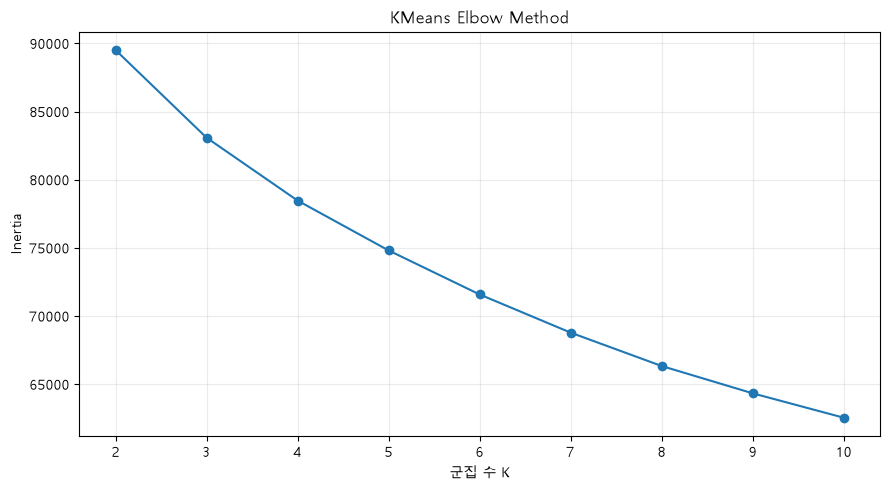

In [17]:
# ============================================================
# K 선택 시각화
# ============================================================

fig, ax = plt.subplots(
    figsize=(9, 5)
)

ax.plot(
    k_result_df["K"],
    k_result_df["Inertia"],
    marker="o",
)

ax.set_title(
    "KMeans Elbow Method"
)

ax.set_xlabel(
    "군집 수 K"
)

ax.set_ylabel(
    "Inertia"
)

ax.grid(
    alpha=0.25
)

plt.tight_layout()
plt.show()

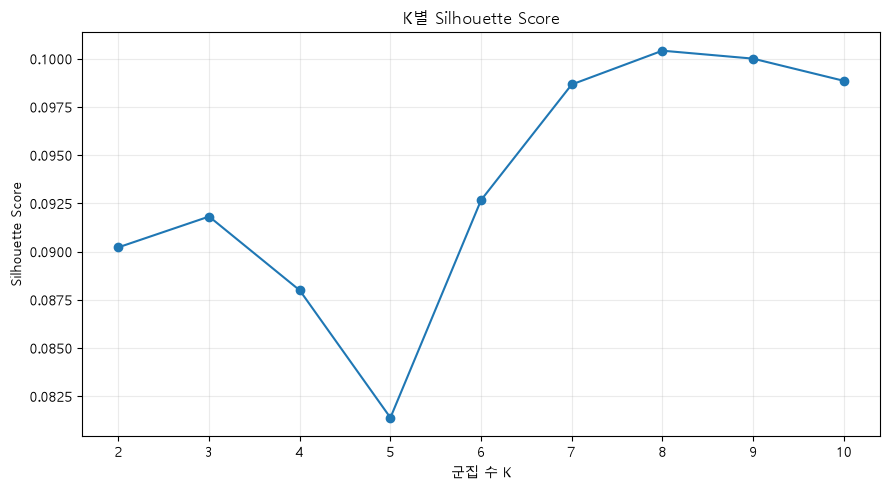

In [16]:
fig, ax = plt.subplots(
    figsize=(9, 5)
)

ax.plot(
    k_result_df["K"],
    k_result_df["Silhouette"],
    marker="o",
)

ax.set_title(
    "K별 Silhouette Score"
)

ax.set_xlabel(
    "군집 수 K"
)

ax.set_ylabel(
    "Silhouette Score"
)

ax.grid(
    alpha=0.25
)

plt.tight_layout()
plt.show()

In [18]:
# ============================================================
# 중복 입지 Feature 축약
# ============================================================

complex_df["교육접근거리_m"] = (
    complex_df[
        [
            "유치원거리_m",
            "초등학교거리_m",
            "중학교거리_m",
            "고등학교거리_m",
        ]
    ]
    .mean(axis=1)
)

In [19]:
# ============================================================
# 군집 V1.1 Feature
# ============================================================

cluster_v11_cols = [
    # 주택
    "전용면적",
    "기준연식",
    "층",

    # 교육
    "교육접근거리_m",

    # 교통
    "역세권거리_m",

    # 생활
    "대규모점포거리_m",

    # 의료
    "응급의료기관거리_m",

    # 업무
    "주요일자리거리_m",
]

print(
    "V1.1 Feature 수:",
    len(cluster_v11_cols),
)

V1.1 Feature 수: 8


In [20]:
# ============================================================
# V1.1 Feature 변환 및 스케일링
# ============================================================

cluster_v11_df = (
    complex_df[
        cluster_v11_cols
    ]
    .copy()
)

log_cols_v11 = [
    "전용면적",
    "교육접근거리_m",
    "역세권거리_m",
    "대규모점포거리_m",
    "응급의료기관거리_m",
    "주요일자리거리_m",
]

for col in log_cols_v11:
    cluster_v11_df[col] = np.log1p(
        cluster_v11_df[col]
    )


scaler_v11 = StandardScaler()

X_cluster_v11 = (
    scaler_v11
    .fit_transform(
        cluster_v11_df
    )
)

print(
    "V1.1:",
    X_cluster_v11.shape,
)

V1.1: (7581, 8)


In [21]:
# ============================================================
# V1.1 KMeans 성능 비교
# ============================================================

v11_results = []

for k in range(2, 11):

    model = KMeans(
        n_clusters=k,
        n_init=20,
        random_state=42,
    )

    labels = model.fit_predict(
        X_cluster_v11
    )

    silhouette = silhouette_score(
        X_cluster_v11,
        labels,
        sample_size=3000,
        random_state=42,
    )

    v11_results.append({
        "K": k,
        "Inertia": model.inertia_,
        "Silhouette": silhouette,
    })


v11_result_df = pd.DataFrame(
    v11_results
)

display(v11_result_df)

,K,Inertia,Silhouette
0,2,52812.367521,0.178503
1,3,47940.806398,0.145120
2,4,44400.651514,0.102530
3,5,41143.044758,0.117035
4,6,38511.451960,0.125752
5,7,36013.775296,0.132254
6,8,34322.283187,0.124249
7,9,32854.499161,0.130235
8,10,31577.649962,0.135765


In [22]:
# ============================================================
# 군집 Feature Set 비교
# ============================================================

cluster_feature_sets = {
    "A_주택특성": [
        "전용면적",
        "기준연식",
        "층",
    ],

    "B_입지접근성": [
        "교육접근거리_m",
        "역세권거리_m",
        "대규모점포거리_m",
        "응급의료기관거리_m",
        "주요일자리거리_m",
    ],

    "C_핵심특성": [
        "전용면적",
        "기준연식",
        "역세권거리_m",
        "주요일자리거리_m",
    ],

    "D_통합": [
        "전용면적",
        "기준연식",
        "층",
        "교육접근거리_m",
        "역세권거리_m",
        "대규모점포거리_m",
        "응급의료기관거리_m",
        "주요일자리거리_m",
    ],
}

In [23]:
# ============================================================
# Feature Set별 KMeans 비교
# ============================================================

def prepare_cluster_data(df, feature_cols):

    data = df[feature_cols].copy()

    log_cols = [
        col
        for col in feature_cols
        if col in [
            "전용면적",
            "교육접근거리_m",
            "역세권거리_m",
            "대규모점포거리_m",
            "응급의료기관거리_m",
            "주요일자리거리_m",
        ]
    ]

    for col in log_cols:
        data[col] = np.log1p(
            data[col]
        )

    scaler = StandardScaler()

    X = scaler.fit_transform(
        data
    )

    return X

In [24]:
comparison_results = []

for set_name, feature_cols in cluster_feature_sets.items():

    X = prepare_cluster_data(
        complex_df,
        feature_cols,
    )

    for k in range(2, 9):

        model = KMeans(
            n_clusters=k,
            n_init=20,
            random_state=42,
        )

        labels = model.fit_predict(X)

        silhouette = silhouette_score(
            X,
            labels,
            sample_size=3000,
            random_state=42,
        )

        comparison_results.append({
            "Feature_Set": set_name,
            "Feature_Count": len(feature_cols),
            "K": k,
            "Silhouette": silhouette,
            "Inertia": model.inertia_,
        })


cluster_compare_df = pd.DataFrame(
    comparison_results
)

display(
    cluster_compare_df.sort_values(
        "Silhouette",
        ascending=False,
    ).head(20)
)

,Feature_Set,Feature_Count,K,Silhouette,Inertia
0,A_주택특성,3,2,0.349154,16460.179868
5,A_주택특성,3,7,0.328748,6662.055796
6,A_주택특성,3,8,0.322206,6034.553807
2,A_주택특성,3,4,0.312942,10448.203110
3,A_주택특성,3,5,0.312942,9189.964848
4,A_주택특성,3,6,0.308358,7914.676897
1,A_주택특성,3,3,0.302586,13120.076934
15,C_핵심특성,4,3,0.264640,19629.459413
14,C_핵심특성,4,2,0.250458,24324.492443
20,C_핵심특성,4,8,0.242069,11471.773561


A_주택특성
→ 가장 높은 분리도
→ K=2 Silhouette 0.349

C_핵심특성
→ 분리도는 조금 낮음
→ 하지만 주택 + 입지 특성을 동시에 반영
→ 메인 군집으로 채택

In [25]:
# ============================================================
# 군집 V1 최종 모델
# ============================================================

FINAL_CLUSTER_COLS = [
    "전용면적",
    "기준연식",
    "역세권거리_m",
    "주요일자리거리_m",
]

FINAL_K = 3


X_cluster_final = prepare_cluster_data(
    complex_df,
    FINAL_CLUSTER_COLS,
)

cluster_model = KMeans(
    n_clusters=FINAL_K,
    n_init=20,
    random_state=42,
)

complex_df["cluster"] = (
    cluster_model.fit_predict(
        X_cluster_final
    )
)

print(
    complex_df["cluster"]
    .value_counts()
    .sort_index()
)

cluster
0    1028
1    4425
2    2128
Name: count, dtype: int64


In [26]:
cluster_size = (
    complex_df["cluster"]
    .value_counts()
    .sort_index()
    .to_frame("단지수")
)

cluster_size["비율_%"] = (
    cluster_size["단지수"]
    / len(complex_df)
    * 100
)

display(cluster_size)

,단지수,비율_%
cluster,,
0,1028,13.560216
1,4425,58.369608
2,2128,28.070175


In [27]:
# ============================================================
# 군집별 대표 특성
# ============================================================

cluster_profile = (
    complex_df
    .groupby("cluster")
    [
        [
            "전용면적",
            "기준연식",
            "역세권거리_m",
            "주요일자리거리_m",
        ]
    ]
    .median()
)

display(
    cluster_profile.round(1)
)

,전용면적,기준연식,역세권거리_m,주요일자리거리_m
cluster,,,,
0,36.7,7.0,351.6,5101.1
1,83.7,22.0,572.3,6115.1
2,84.3,24.0,331.3,1959.3


In [28]:
# ============================================================
# 군집 추가 특성 분석
# ============================================================

profile_cols = [
    "전용면적",
    "기준연식",
    "역세권거리_m",
    "주요일자리거리_m",

    # 군집에 사용하지 않은 입지 특성
    "교육접근거리_m",
    "응급의료기관거리_m",
    "대규모점포거리_m",
]

cluster_detail = (
    complex_df
    .groupby("cluster")[profile_cols]
    .median()
)

display(
    cluster_detail.round(1)
)

,전용면적,기준연식,역세권거리_m,주요일자리거리_m,교육접근거리_m,응급의료기관거리_m,대규모점포거리_m
cluster,,,,,,,
0,36.7,7.0,351.6,5101.1,499.9,932.1,421.2
1,83.7,22.0,572.3,6115.1,427.3,1163.1,594.5
2,84.3,24.0,331.3,1959.3,479.4,942.0,518.3


In [29]:
# ============================================================
# 거래 데이터에 군집 Label 연결
# ============================================================

cluster_map = (
    complex_df[
        [
            "단지일련번호",
            "cluster",
        ]
    ]
    .copy()
)

cluster_train_labeled = (
    cluster_train_df
    .merge(
        cluster_map,
        on="단지일련번호",
        how="left",
    )
)

In [30]:
# ============================================================
# 군집별 가격 특성
# ============================================================

cluster_price_profile = (
    cluster_train_labeled
    .groupby("cluster")
    .agg(
        거래건수=(
            "transaction_id",
            "size",
        ),
        거래가격_중위값=(
            "거래금액",
            "median",
        ),
        전용면적_중위값=(
            "전용면적",
            "median",
        ),
    )
)

display(
    cluster_price_profile.round(1)
)

,거래건수,거래가격_중위값,전용면적_중위값
cluster,,,
0,29866,80000.0,59.1
1,112774,86000.0,83.3
2,52093,139500.0,84.6


In [31]:
# ============================================================
# 군집 이름 부여
# ============================================================

cluster_name_map = {
    0: "소형·신축 역세권형",
    1: "일반 주거형",
    2: "업무지·역세권 고가형",
}

complex_df["cluster_name"] = (
    complex_df["cluster"]
    .map(cluster_name_map)
)

display(
    complex_df[
        [
            "단지일련번호",
            "단지명",
            "cluster",
            "cluster_name",
        ]
    ].head()
)

,단지일련번호,단지명,cluster,cluster_name
0,11110-101,크래스빌,1,일반 주거형
1,11110-102,현대뜨레비앙,2,업무지·역세권 고가형
2,11110-107,경희궁파크팰리스,2,업무지·역세권 고가형
3,11110-111,창림,2,업무지·역세권 고가형
4,11110-112,신현(102동),1,일반 주거형


In [32]:
# ============================================================
# 2026 Test 단지 Coverage 확인
# ============================================================

train_complex_ids = set(
    complex_df["단지일련번호"]
)

test_complex_ids = set(
    cluster_test_df["단지일련번호"]
)

known_complex_ids = (
    test_complex_ids
    & train_complex_ids
)

new_complex_ids = (
    test_complex_ids
    - train_complex_ids
)

print(
    "Test 전체 단지:",
    f"{len(test_complex_ids):,}",
)

print(
    "기존 단지:",
    f"{len(known_complex_ids):,}",
)

print(
    "신규 단지:",
    f"{len(new_complex_ids):,}",
)

print(
    "단지 Coverage:",
    f"{len(known_complex_ids) / len(test_complex_ids) * 100:.2f}%",
)

Test 전체 단지: 5,038
기존 단지: 4,748
신규 단지: 290
단지 Coverage: 94.24%


In [33]:
# ============================================================
# Test 거래 기준 군집 Coverage
# ============================================================

test_cluster_check = (
    cluster_test_df[
        [
            "transaction_id",
            "단지일련번호",
        ]
    ]
    .merge(
        complex_df[
            [
                "단지일련번호",
                "cluster",
                "cluster_name",
            ]
        ],
        on="단지일련번호",
        how="left",
    )
)

total_transactions = len(
    test_cluster_check
)

known_transactions = (
    test_cluster_check["cluster"]
    .notna()
    .sum()
)

new_transactions = (
    test_cluster_check["cluster"]
    .isna()
    .sum()
)

print(
    "Test 전체 거래:",
    f"{total_transactions:,}",
)

print(
    "군집 연결 거래:",
    f"{known_transactions:,}",
)

print(
    "신규 단지 거래:",
    f"{new_transactions:,}",
)

print(
    "거래 Coverage:",
    f"{known_transactions / total_transactions * 100:.2f}%",
)

Test 전체 거래: 39,569
군집 연결 거래: 38,662
신규 단지 거래: 907
거래 Coverage: 97.71%


In [34]:
# ============================================================
# 회귀 V1 Test 예측 결과 로드
# ============================================================

REGRESSION_RESULT_PATH = (
    PROJECT_DIR
    / "model"
    / "regression"
    / "v1"
    / "test_predictions.parquet"
)

regression_test = pd.read_parquet(
    REGRESSION_RESULT_PATH
)

print(
    "회귀 Test:",
    regression_test.shape,
)

print(
    "transaction_id 중복:",
    regression_test[
        "transaction_id"
    ].duplicated().sum(),
)

회귀 Test: (39569, 7)
transaction_id 중복: 0


In [35]:
# ============================================================
# 회귀 예측 결과와 군집 연결
# ============================================================

regression_cluster_test = (
    regression_test
    .merge(
        test_cluster_check,
        on="transaction_id",
        how="left",
    )
)

print(
    "전체 Test:",
    len(regression_cluster_test),
)

print(
    "군집 연결:",
    regression_cluster_test[
        "cluster"
    ].notna().sum(),
)

print(
    "군집 미연결:",
    regression_cluster_test[
        "cluster"
    ].isna().sum(),
)

전체 Test: 39569
군집 연결: 38662
군집 미연결: 907


In [36]:
# ============================================================
# 군집별 회귀 성능
# ============================================================

known_test = (
    regression_cluster_test
    .dropna(
        subset=["cluster"]
    )
    .copy()
)

known_test["예측오차"] = (
    known_test["예측가격"]
    - known_test["실제가격"]
)

known_test["오차10이내"] = (
    known_test["오차율"]
    <= 10
)

cluster_regression_profile = (
    known_test
    .groupby(
        [
            "cluster",
            "cluster_name",
        ]
    )
    .agg(
        거래건수=(
            "transaction_id",
            "size",
        ),
        실제가격_중위값=(
            "실제가격",
            "median",
        ),
        MAE_만원=(
            "절대오차",
            "mean",
        ),
        MAPE=(
            "오차율",
            "mean",
        ),
        평균예측오차_만원=(
            "예측오차",
            "mean",
        ),
        오차10이내율=(
            "오차10이내",
            "mean",
        ),
    )
    .reset_index()
)

cluster_regression_profile[
    "오차10이내율"
] *= 100

display(
    cluster_regression_profile.round(2)
)

,cluster,cluster_name,거래건수,실제가격_중위값,MAE_만원,MAPE,평균예측오차_만원,오차10이내율
0,0.0,소형·신축 역세권형,4343,103000.0,10081.37,9.20,-5879.97,63.71
1,1.0,일반 주거형,25761,85500.0,9314.68,8.96,-5497.28,64.19
2,2.0,업무지·역세권 고가형,8558,143000.0,15477.32,9.58,-4520.31,62.57


업무지·역세권 고가형 군집은 다른 유형보다 절대오차와 비율오차가 높아 회귀 난도가 상대적으로 높았으나, 전체적인 과소예측 현상이 특정 군집에만 집중되지는 않았다.

In [37]:
# ============================================================
# 군집 × 가격대 회귀 성능
# ============================================================

price_bins = [
    0,
    50_000,
    100_000,
    150_000,
    200_000,
    np.inf,
]

price_labels = [
    "5억 이하",
    "5~10억",
    "10~15억",
    "15~20억",
    "20억 초과",
]

known_test["가격대"] = pd.cut(
    known_test["실제가격"],
    bins=price_bins,
    labels=price_labels,
    right=False,
)

In [38]:
cluster_price_error = (
    known_test
    .groupby(
        [
            "cluster_name",
            "가격대",
        ],
        observed=True,
    )
    .agg(
        거래건수=(
            "transaction_id",
            "size",
        ),
        MAPE=(
            "오차율",
            "mean",
        ),
        평균예측오차_만원=(
            "예측오차",
            "mean",
        ),
    )
    .reset_index()
)

display(
    cluster_price_error.round(2)
)

,cluster_name,가격대,거래건수,MAPE,평균예측오차_만원
0,소형·신축 역세권형,5억 이하,1078,10.63,190.66
1,소형·신축 역세권형,5~10억,1041,9.19,-1194.42
2,소형·신축 역세권형,10~15억,994,8.86,-8373.32
3,소형·신축 역세권형,15~20억,661,9.48,-13237.59
4,소형·신축 역세권형,20억 초과,569,6.79,-13050.49
5,업무지·역세권 고가형,5억 이하,484,13.14,3016.80
6,업무지·역세권 고가형,5~10억,2324,10.16,-1343.48
7,업무지·역세권 고가형,10~15억,1749,10.99,-8840.29
8,업무지·역세권 고가형,15~20억,1413,9.05,-6699.42
9,업무지·역세권 고가형,20억 초과,2588,7.72,-4673.41


고가형 군집이라서 과소예측하는 것이 아니라, 동일 군집 내부에서도 가격 수준에 따라 예측 편향이 달라진다.

In [39]:
# ============================================================
# 군집 × 가격대 최종 회귀 성능
# ============================================================

cluster_price_error_final = (
    known_test
    .groupby(
        [
            "cluster_name",
            "가격대",
        ],
        observed=True,
    )
    .agg(
        거래건수=(
            "transaction_id",
            "size",
        ),
        실제가격_중위값=(
            "실제가격",
            "median",
        ),
        MAE_만원=(
            "절대오차",
            "mean",
        ),
        MAPE=(
            "오차율",
            "mean",
        ),
        평균예측오차_만원=(
            "예측오차",
            "mean",
        ),
    )
    .reset_index()
)

display(
    cluster_price_error_final.round(2)
)

,cluster_name,가격대,거래건수,실제가격_중위값,MAE_만원,MAPE,평균예측오차_만원
0,소형·신축 역세권형,5억 이하,1078,20500.0,2464.25,10.63,190.66
1,소형·신축 역세권형,5~10억,1041,77000.0,6773.34,9.19,-1194.42
2,소형·신축 역세권형,10~15억,994,126050.0,11332.53,8.86,-8373.32
3,소형·신축 역세권형,15~20억,661,170000.0,16208.52,9.48,-13237.59
4,소형·신축 역세권형,20억 초과,569,248000.0,21261.03,6.79,-13050.49
5,업무지·역세권 고가형,5억 이하,484,40000.0,4708.80,13.14,3016.80
6,업무지·역세권 고가형,5~10억,2324,74725.0,7687.68,10.16,-1343.48
7,업무지·역세권 고가형,10~15억,1749,125500.0,13759.27,10.99,-8840.29
8,업무지·역세권 고가형,15~20억,1413,170000.0,15424.93,9.05,-6699.42
9,업무지·역세권 고가형,20억 초과,2588,299250.0,25675.93,7.72,-4673.41


V1
전용면적
기준연식
역세권거리
주요일자리거리

V2 후보
+ 육아초등접근거리
+ 중고등접근거리

In [40]:
# ============================================================
# 군집 V1 최종 검증
# ============================================================

final_silhouette = silhouette_score(
    X_cluster_final,
    complex_df["cluster"],
    sample_size=3000,
    random_state=42,
)

final_cluster_size = (
    complex_df["cluster"]
    .value_counts()
    .sort_index()
)

print("===== 군집 V1 최종 검증 =====")
print(f"단지 수       : {len(complex_df):,}")
print(f"Feature 수    : {len(FINAL_CLUSTER_COLS)}")
print(f"K             : {FINAL_K}")
print(f"Silhouette    : {final_silhouette:.4f}")

print("\n군집별 단지 수")
print(final_cluster_size)

===== 군집 V1 최종 검증 =====
단지 수       : 7,581
Feature 수    : 4
K             : 3
Silhouette    : 0.2646

군집별 단지 수
cluster
0    1028
1    4425
2    2128
Name: count, dtype: int64


In [41]:
# ============================================================
# 군집 V1 최종 프로파일
# ============================================================

final_cluster_profile = (
    complex_df
    .groupby(
        [
            "cluster",
            "cluster_name",
        ]
    )
    .agg(
        단지수=("단지일련번호", "size"),
        전용면적=("전용면적", "median"),
        기준연식=("기준연식", "median"),
        역세권거리_m=("역세권거리_m", "median"),
        주요일자리거리_m=("주요일자리거리_m", "median"),
    )
    .reset_index()
)

final_cluster_profile["단지비율_%"] = (
    final_cluster_profile["단지수"]
    / len(complex_df)
    * 100
)

display(
    final_cluster_profile.round(2)
)

,cluster,cluster_name,단지수,전용면적,기준연식,역세권거리_m,주요일자리거리_m,단지비율_%
0,0,소형·신축 역세권형,1028,36.66,7.0,351.59,5101.15,13.56
1,1,일반 주거형,4425,83.70,22.0,572.30,6115.12,58.37
2,2,업무지·역세권 고가형,2128,84.26,24.0,331.31,1959.31,28.07


In [43]:
# ============================================================
# 군집 V1 최종 모델 확정
# ============================================================

FINAL_CLUSTER_COLS = [
    "전용면적",
    "기준연식",
    "역세권거리_m",
    "주요일자리거리_m",
]

FINAL_K = 3

final_log_cols = [
    "전용면적",
    "역세권거리_m",
    "주요일자리거리_m",
]

cluster_name_map = {
    0: "소형·신축 역세권형",
    1: "일반 주거형",
    2: "업무지·역세권 고가형",
}


# 군집용 데이터
final_cluster_df = (
    complex_df[FINAL_CLUSTER_COLS]
    .copy()
)

for col in final_log_cols:
    final_cluster_df[col] = np.log1p(
        final_cluster_df[col]
    )


# StandardScaler
final_cluster_scaler = StandardScaler()

X_cluster_final = (
    final_cluster_scaler
    .fit_transform(final_cluster_df)
)


# KMeans
final_cluster_model = KMeans(
    n_clusters=FINAL_K,
    n_init=20,
    random_state=42,
)

complex_df["cluster"] = (
    final_cluster_model
    .fit_predict(X_cluster_final)
)

complex_df["cluster_name"] = (
    complex_df["cluster"]
    .map(cluster_name_map)
)


# 최종 Silhouette
final_silhouette = silhouette_score(
    X_cluster_final,
    complex_df["cluster"],
    sample_size=3000,
    random_state=42,
)

print("===== 군집 V1 최종 모델 =====")
print(f"단지 수    : {len(complex_df):,}")
print(f"Feature 수 : {len(FINAL_CLUSTER_COLS)}")
print(f"K          : {FINAL_K}")
print(f"Silhouette : {final_silhouette:.4f}")

print("\n군집별 단지 수")
print(
    complex_df["cluster"]
    .value_counts()
    .sort_index()
)

===== 군집 V1 최종 모델 =====
단지 수    : 7,581
Feature 수 : 4
K          : 3
Silhouette : 0.2646

군집별 단지 수
cluster
0    1028
1    4425
2    2128
Name: count, dtype: int64


In [44]:
# ============================================================
# 군집 V1 산출물 저장
# ============================================================

import json
import joblib


CLUSTERING_DIR = (
    PROJECT_DIR
    / "model"
    / "clustering"
    / "v1"
)

CLUSTERING_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


# 1. KMeans 모델
joblib.dump(
    final_cluster_model,
    CLUSTERING_DIR
    / "kmeans_baseline.joblib",
)


# 2. Scaler
joblib.dump(
    final_cluster_scaler,
    CLUSTERING_DIR
    / "scaler.joblib",
)


# 3. 설정
cluster_config = {
    "version": "v1",
    "algorithm": "KMeans",
    "unit": "apartment_complex",
    "k": int(FINAL_K),
    "features": FINAL_CLUSTER_COLS,
    "log_features": final_log_cols,
    "silhouette": float(
        final_silhouette
    ),
    "random_state": 42,
    "cluster_names": {
        str(k): v
        for k, v
        in cluster_name_map.items()
    },
}

with open(
    CLUSTERING_DIR
    / "cluster_config.json",
    "w",
    encoding="utf-8",
) as f:
    json.dump(
        cluster_config,
        f,
        ensure_ascii=False,
        indent=2,
    )

In [45]:
# ============================================================
# 군집 V1 결과 파일 저장
# ============================================================

# 1. 단지별 군집 결과
complex_df.to_parquet(
    CLUSTERING_DIR
    / "complex_clusters.parquet",
    index=False,
)


# 2. 군집 프로파일
final_cluster_profile.to_csv(
    CLUSTERING_DIR
    / "cluster_profile.csv",
    index=False,
    encoding="utf-8-sig",
)


# 3. Feature Set 비교 결과
cluster_compare_df.to_csv(
    CLUSTERING_DIR
    / "feature_set_comparison.csv",
    index=False,
    encoding="utf-8-sig",
)


# 4. 군집별 회귀 성능
cluster_regression_profile.to_csv(
    CLUSTERING_DIR
    / "cluster_regression_metrics.csv",
    index=False,
    encoding="utf-8-sig",
)


# 5. 군집 × 가격대 회귀 성능
cluster_price_error_final.to_csv(
    CLUSTERING_DIR
    / "cluster_price_error.csv",
    index=False,
    encoding="utf-8-sig",
)

print("군집 V1 결과 파일 저장 완료")

군집 V1 결과 파일 저장 완료


In [46]:
# ============================================================
# 군집 V1 최종 저장 확인
# ============================================================

print("===== 군집 V1 저장 파일 =====")

for file in sorted(
    CLUSTERING_DIR.iterdir()
):
    print("-", file.name)

===== 군집 V1 저장 파일 =====
- cluster_config.json
- cluster_price_error.csv
- cluster_profile.csv
- cluster_regression_metrics.csv
- complex_clusters.parquet
- feature_set_comparison.csv
- kmeans_baseline.joblib
- scaler.joblib
